# Fig 2c: Reported rack power by year

Supports Section 2.1, paragraph 3: rack power has risen, especially in AI-oriented infrastructure. The points are **reported values by system generation, not a continuous series**.

**Source:** `Data/generated/racks.csv`. Values marked `~` still need checking against primary sources. Their labels keep the `~`.

The notebook makes two figures:
1. **Main figure** (`fig2c_rack_power`): AI systems vs. HPC systems only. Hollow = announced. The figure doesn't show how each value was obtained; that's recorded in `rack_kW_basis` and `source_url`.
2. **Reference figure** (`fig2c_rack_power_reference`): colour = cooling (air vs. liquid), plus the Uptime Institute survey average and OCP rack design limits as grey references, with `~` on unverified values.

Rows without a `rack_kW` value aren't plotted. The notebook lists them at the end so the gaps are visible.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from pathlib import Path

DATA = Path('../Data')
OUT = Path('../figures'); OUT.mkdir(exist_ok=True)

# Reference categorical palette, slots 1-2 (validated all-pairs); neutral grey for reference values
C_LIQUID, C_AIR, C_REF = '#2a78d6', '#eb6834', '#8a8984'
TEXT, TEXT_2, GRID = '#0b0b0b', '#52514e', '#e4e3df'

## Load

In [6]:
racks = pd.read_csv(DATA / 'generated/racks.csv', dtype=str)

def parse(col):
    """'~120' -> (120.0, True); '120' -> (120.0, False); blank -> (NaN, False)"""
    s = racks[col].fillna('')
    return pd.to_numeric(s.str.lstrip('~'), errors='coerce'), s.str.startswith('~')

racks['kW'], racks['kW_verify'] = parse('rack_kW')
racks['year'] = racks['year'].astype(int)

def cooling_class(c):
    c = str(c).lstrip('~').lower()
    if 'immersion' in c: return 'immersion'
    if c.startswith('dlc') or 'liquid' in c: return 'liquid'
    if c.startswith('air'): return 'air'
    return 'other'

racks['cooling_class'] = racks['cooling'].map(cooling_class)
plotted = racks.dropna(subset=['kW'])
plotted[['system', 'year', 'category', 'cooling', 'cooling_class', 'rack_kW', 'status']]

,system,year,category,cooling,cooling_class,rack_kW,status
0,Uptime survey average rack density 2017,2017,survey_baseline,mixed,other,~5.6,shipped
1,Uptime survey average rack density 2020,2020,survey_baseline,mixed,other,~8.4,shipped
2,Uptime survey average rack density 2024,2024,survey_baseline,mixed,other,~8,shipped
4,Uptime survey modal rack density 2026,2026,survey_baseline,mixed,other,~11,shipped
9,Open Rack v3 (OCP),2021,design_envelope,air,air,18,shipped
11,Mt Diablo / Diablo 400 (OCP),2025,design_envelope,DLC,liquid,1000,announced
12,IBM BlueGene/L (LLNL),2005,hpc,air,air,22,shipped
13,Cray XT5 Jaguar (ORNL),2009,hpc,air+refrigerant,air,35,shipped
14,IBM BlueGene/Q Sequoia (LLNL),2012,hpc,DLC,liquid,82,shipped
15,Cray XK7 Titan (ORNL),2012,hpc,air+refrigerant,air,41,shipped


## Labels

In [7]:
# Short display names; (dx years, dy as a multiplicative factor on kW, ha), tuned by eye after rendering
SHORT = {
    'IBM BlueGene/L (LLNL)': ('IBM BlueGene/L', (0.3, 1.0, 'left')),
    'Cray XT5 Jaguar (ORNL)': ('Cray XT5 Jaguar', (0.3, 1.0, 'left')),
    'IBM BlueGene/Q Sequoia (LLNL)': ('IBM BlueGene/Q Sequoia', (-0.3, 1.0, 'right')),
    'Cray XK7 Titan (ORNL)': ('Cray XK7 Titan', (0.3, 1.0, 'left')),
    'IBM Summit AC922 (ORNL)': ('IBM Summit', (-0.3, 1.25, 'right')),
    'Fujitsu Fugaku (RIKEN)': ('Fujitsu Fugaku', (-0.3, 1.0, 'right')),
    'HPE Cray EX Frontier (ORNL)': ('HPE Frontier (AMD)', (-0.3, 1.0, 'right')),
    'HPE Cray EX Aurora (ANL)': ('HPE Aurora (Intel)', (-0.3, 1.05, 'right')),
    'HPE Cray EX El Capitan (LLNL)': ('HPE El Capitan (AMD)', (-0.3, 1.08, 'right')),
    'NVIDIA DGX-1 (P100)': ('NVIDIA DGX-1', (-0.3, 1.0, 'right')),
    'NVIDIA DGX-2 (V100)': ('NVIDIA DGX-2', (0.3, 1.12, 'left')),
    'NVIDIA DGX A100 SuperPOD': ('NVIDIA DGX A100', (0, 0.84, 'center')),
    'NVIDIA DGX H100 SuperPOD': ('NVIDIA DGX H100', (0.3, 0.88, 'left')),
    'NVIDIA DGX B200': ('NVIDIA DGX B200', (0.3, 1.0, 'left')),
    'NVIDIA GB200 NVL72': ('NVIDIA GB200 NVL72', (-0.3, 0.92, 'right')),
    'Meta Catalina (GB200)': ('Meta Catalina', (-0.3, 1.1, 'right')),
    'NVIDIA GB300 NVL72': ('NVIDIA GB300 NVL72', (0.3, 1.0, 'left')),
    'AMD Instinct MI355X platform': ('AMD MI355X rack', (0.3, 0.88, 'left')),
    'NVIDIA Vera Rubin NVL72': ('NVIDIA Vera Rubin NVL72', (0.3, 0.97, 'left')),
    'AMD Helios (MI400 series)': ('AMD Helios', (0.3, 1.12, 'left')),
    'NVIDIA Rubin Ultra NVL576 (Kyber)': ('NVIDIA Kyber NVL576', (-0.3, 1.0, 'right')),
    'Google TPU v7 Ironwood superpod': ('Google TPU v7', (0.3, 1.0, 'left')),
    'Tesla Dojo ExaPOD cabinet': ('Tesla Dojo', (-0.3, 0.95, 'right')),
    'Huawei CloudMatrix 384': ('Huawei CloudMatrix 384', (0.3, 1.05, 'left')),
    'Open Rack v3 (OCP)': ('OCP Open Rack v3', (0.3, 1.0, 'left')),
    'Mt Diablo / Diablo 400 (OCP)': ('OCP Mt Diablo (power-delivery limit)', (-0.3, 1.0, 'right')),
}
# Small x-offsets (years) so systems with near-identical year and power don't sit on top of each other
JITTER = {'IBM Summit AC922 (ORNL)': -0.15, 'NVIDIA DGX-2 (V100)': 0.15,
          'NVIDIA GB200 NVL72': -0.12, 'Meta Catalina (GB200)': 0.12}
MARKER = {'ai_accelerator': 'o', 'hpc': 's', 'design_envelope': 'D'}

## Main figure: AI vs. HPC

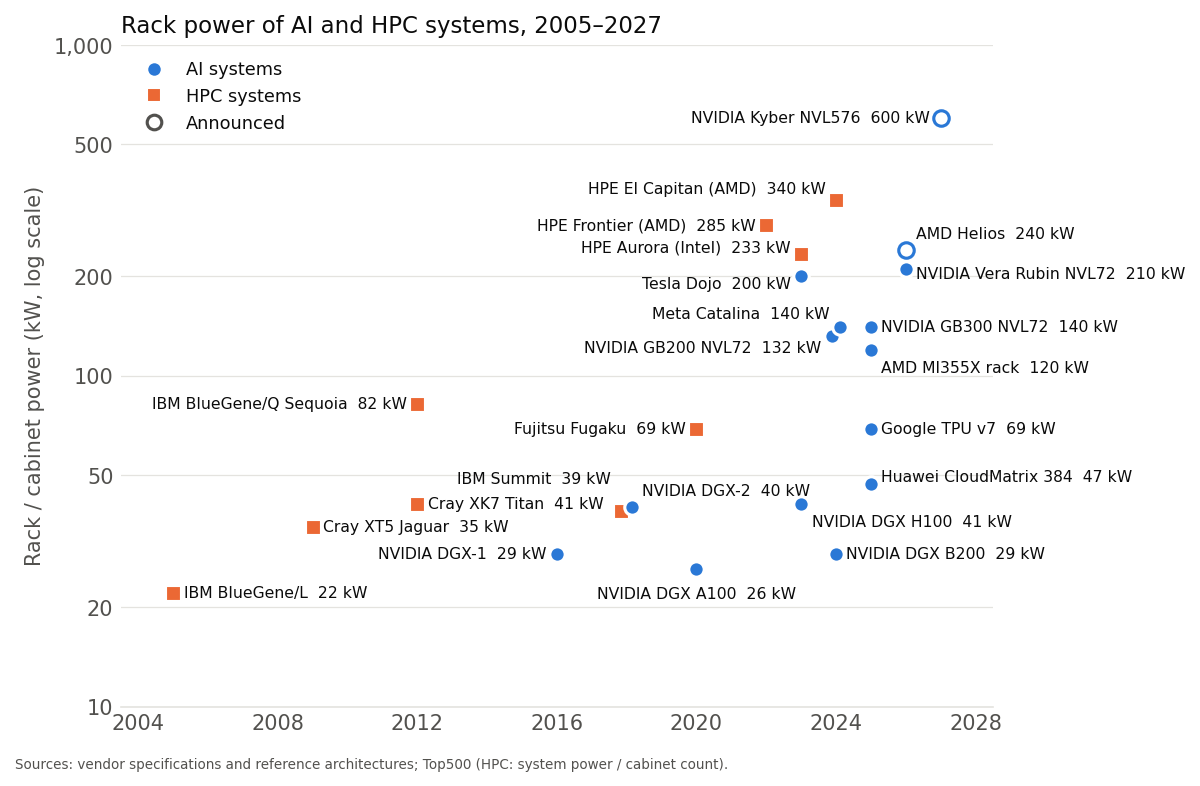

In [8]:
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'axes.edgecolor': GRID,
                     'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2})

GROUP = {'ai_accelerator': ('AI systems', C_LIQUID, 'o'), 'hpc': ('HPC systems', C_AIR, 's')}
main = plotted[plotted['category'].isin(GROUP)]

fig, ax = plt.subplots(figsize=(8, 5.2), dpi=150)
for _, r in main.iterrows():
    _, color, marker = GROUP[r['category']]
    hollow = r['status'] == 'announced'
    x = r['year'] + JITTER.get(r['system'], 0)
    ax.scatter(x, r['kW'], s=55, marker=marker, linewidth=1.5, zorder=4,
               facecolor='white' if hollow else color, edgecolor=color if hollow else 'white')
    name, (dx, fy, ha) = SHORT.get(r['system'], (r['system'], (0.3, 1.0, 'left')))
    ax.annotate(f"{name}  {r['kW']:.0f} kW", xy=(x, r['kW']), xytext=(x + dx, r['kW'] * fy),
                fontsize=7.5, color=TEXT, va='center', ha=ha)

ax.set_yscale('log')
ax.yaxis.set_major_locator(FixedLocator([10, 20, 50, 100, 200, 500, 1000]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylim(10, 1000)
ax.set_xlim(2003.5, 2028.5)
ax.set_xticks(range(2004, 2029, 4))
ax.set_ylabel('Rack / cabinet power (kW, log scale)')
ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
legend = [Line2D([], [], ls='', marker=m, ms=7, mfc=c, mec='white', label=l) for l, c, m in GROUP.values()]
legend.append(Line2D([], [], ls='', marker='o', ms=7, mfc='white', mec='#52514e', mew=1.5, label='Announced'))
ax.legend(handles=legend, loc='upper left', frameon=False, fontsize=8.5, labelcolor=TEXT)
ax.set_title('Rack power of AI and HPC systems, 2005–2027', loc='left', fontsize=11, color=TEXT)
fig.text(0.01, 0.005, 'Sources: vendor specifications and reference architectures; Top500 (HPC: system power / cabinet count).',
         fontsize=6.5, color=TEXT_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(OUT / 'fig2c_rack_power.pdf')
fig.savefig(OUT / 'fig2c_rack_power.png', dpi=200)
plt.show()

## Reference figure: cooling type, survey average and OCP design limits

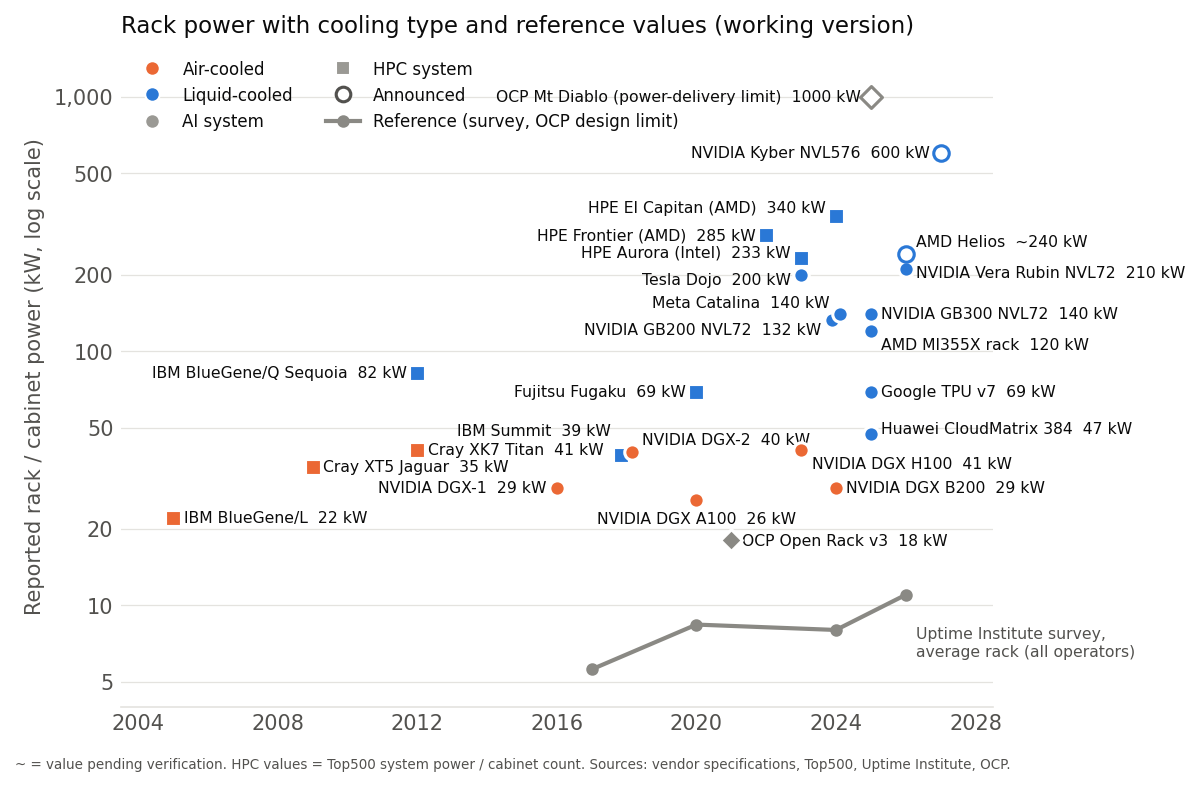

In [9]:
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'axes.edgecolor': GRID,
                     'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2})
fig, ax = plt.subplots(figsize=(8, 5.2), dpi=150)

# Survey baseline as a reference line
survey = plotted[plotted['category'] == 'survey_baseline'].sort_values('year')
ax.plot(survey['year'], survey['kW'], color=C_REF, lw=2, marker='o', ms=5, zorder=2)
last = survey.iloc[-1]
ax.annotate('Uptime Institute survey,\naverage rack (all operators)', xy=(last['year'], last['kW']),
            xytext=(last['year'] + 0.3, last['kW'] * 0.75), fontsize=7.5, color=TEXT_2, va='top')

for _, r in plotted[plotted['category'] != 'survey_baseline'].iterrows():
    if r['category'] == 'design_envelope':
        color = C_REF
    else:
        color = C_LIQUID if r['cooling_class'] == 'liquid' else C_AIR
    hollow = r['status'] == 'announced'
    x = r['year'] + JITTER.get(r['system'], 0)
    ax.scatter(x, r['kW'], s=55, marker=MARKER.get(r['category'], 'o'), linewidth=1.5, zorder=4,
               facecolor='white' if hollow else color, edgecolor=color if hollow else 'white')
    name, (dx, fy, ha) = SHORT.get(r['system'], (r['system'], (0.3, 1.0, 'left')))
    value = f"{'~' if r['kW_verify'] else ''}{r['kW']:.0f} kW"
    ax.annotate(f'{name}  {value}', xy=(x, r['kW']), xytext=(x + dx, r['kW'] * fy),
                fontsize=7.5, color=TEXT, va='center', ha=ha)

ax.set_yscale('log')
ticks = [5, 10, 20, 50, 100, 200, 500, 1000]
ax.yaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylim(4, 1600)
ax.set_xlim(2003.5, 2028.5)
ax.set_xticks(range(2004, 2029, 4))
ax.set_ylabel('Reported rack / cabinet power (kW, log scale)')
ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)

legend = [
    Line2D([], [], ls='', marker='o', ms=7, mfc=C_AIR, mec='white', label='Air-cooled'),
    Line2D([], [], ls='', marker='o', ms=7, mfc=C_LIQUID, mec='white', label='Liquid-cooled'),
    Line2D([], [], ls='', marker='o', ms=7, mfc='#9a9994', mec='white', label='AI system'),
    Line2D([], [], ls='', marker='s', ms=7, mfc='#9a9994', mec='white', label='HPC system'),
    Line2D([], [], ls='', marker='o', ms=7, mfc='white', mec='#52514e', mew=1.5, label='Announced'),
    Line2D([], [], color=C_REF, lw=2, marker='o', ms=5, label='Reference (survey, OCP design limit)'),
]
ax.legend(handles=legend, loc='upper left', frameon=False, fontsize=8, labelcolor=TEXT, ncol=2)
ax.set_title('Rack power with cooling type and reference values (working version)', loc='left', fontsize=11, color=TEXT)
fig.text(0.01, 0.005, '~ = value pending verification. HPC values = Top500 system power / cabinet count. '
         'Sources: vendor specifications, Top500, Uptime Institute, OCP.', fontsize=6.5, color=TEXT_2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(OUT / 'fig2c_rack_power_reference.pdf')
fig.savefig(OUT / 'fig2c_rack_power_reference.png', dpi=200)
plt.show()

## Gaps: rows not yet plotted (no rack_kW)

In [10]:
racks[racks['kW'].isna()][['system', 'vendor', 'category', 'year', 'status', 'cooling']]

,system,vendor,category,year,status,cooling
3,Uptime survey average rack density 2025,Uptime Institute,survey_baseline,2025,shipped,mixed
5,Rack of 1U dual-socket Xeon 5160 servers,Intel (generic OEM),general_purpose,2006,shipped,air
6,Rack of 1U dual-socket Xeon E5-2680 v3 servers,Intel (generic OEM),general_purpose,2014,shipped,air
7,Rack of 2U dual-socket EPYC 9654 servers,AMD (generic OEM),general_purpose,2022,shipped,air
8,Open Rack v1 (OCP),Open Compute Project,design_envelope,2013,shipped,air
10,Open Rack v3 HPR (OCP),Open Compute Project,design_envelope,2024,shipped,~DLC
16,Tianhe-2 (NUDT),NUDT/Inspur,hpc,2013,shipped,~liquid-assisted
22,Google TPU v2 pod,Google,ai_accelerator,2017,shipped,air
23,Google TPU v3 pod,Google,ai_accelerator,2018,shipped,DLC
24,Google TPU v4 pod,Google,ai_accelerator,2021,shipped,DLC
